# LAB 04 — Text Classification
## Experiment 1 — Dataset Inspection

IMDb Movie Reviews từ Hugging Face, task binary sentiment classification: 0 = Negative, 1 = Positive. Chỉ dùng split train và test gốc; không dùng unsupervised. Phần này chỉ inspection: không preprocessing để train, không sửa/xóa sample, không huấn luyện classifier.


## 0. Dependencies

Nếu thiếu package, chạy trong cell riêng rồi restart kernel:

    %pip install datasets pandas numpy matplotlib seaborn


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")
from datasets import load_dataset
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 300)


/home/nguyenducthang/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Task 1 — Dataset overview

Nạp riêng train/test, in số sample và class quan sát được, rồi hiển thị năm sample đầu mỗi split.


In [2]:
DATASET_NAME = "stanfordnlp/imdb"
LABEL_NAMES = {0: "Negative", 1: "Positive"}

imdb = load_dataset(DATASET_NAME)
train_data, test_data = imdb["train"], imdb["test"]
train_df, test_df = train_data.to_pandas(), test_data.to_pandas()
all_df = pd.concat([train_df, test_df], ignore_index=True)

observed_labels = all_df["label"].dropna().unique()
print("Dataset:", DATASET_NAME)
print("Train samples:", f"{len(train_df):,}")
print("Test samples:", f"{len(test_df):,}")
print("Total labeled samples:", f"{len(all_df):,}")
print("Observed number of classes:", len(observed_labels))
print("Observed label values:", sorted(observed_labels.tolist()))
print()
print("First five train samples:")
display(train_df[["text", "label"]].head(5))
print("First five test samples:")
display(test_df[["text", "label"]].head(5))


Using the latest cached version of the dataset since stanfordnlp/imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at /home/nguyenducthang/.cache/huggingface/datasets/stanfordnlp___imdb/plain_text/0.0.0/e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Sun Oct 11 22:27:54 2026).


Dataset: stanfordnlp/imdb
Train samples: 25,000
Test samples: 25,000
Total labeled samples: 50,000
Observed number of classes: 2
Observed label values: [0, 1]

First five train samples:


,text,label
0,"I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered ""controversial"" I real...",0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nu...",0
2,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might feel virtuous for sitting thru it because it touches on so many IMPORTANT issues but it does so without any discernable motive. The viewer comes away...,0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements and those are, (1) the realistic acting (2) the impressive, undeservedly good, photo. Apart from that, what strikes me most is the endless stream of ...",0
4,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee song..<br /><br />""Is that all there is??"" ...I was just an early teen when this smoked fish hit the U.S. I was too young to get in the theater (although I did manage to sneak into ""...",0


First five test samples:


,text,label
0,"I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogue...",0
1,"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handle...",0
2,its a totally average film with a few semi-alright action sequences that make the plot seem a little better and remind the viewer of the classic van dam films. parts of the plot don't make sense and seem to be added in to use up time. the end plot is that of a very basic type that doesn't leave ...,0
3,"STAR RATING: ***** Saturday Night **** Friday Night *** Friday Morning ** Sunday Night * Monday Morning <br /><br />Former New Orleans homicide cop Jack Robideaux (Jean Claude Van Damme) is re-assigned to Columbus, a small but violent town in Mexico to help the police there with their efforts to...",0
4,"First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other ...",0


### Giải thích

Chỉ lấy split train/test từ dataset và thống kê trực tiếp trên dữ liệu gốc. Năm review đầu được hiển thị nguyên văn; không truy cập split unsupervised.


## Task 2 — Class distribution

Tạo bảng Class, Count, Percentage cho train/test/overall và vẽ biểu đồ riêng cho train, test.



Train


,Class,Count,Percentage
0,Negative,12500,50.00%
1,Positive,12500,50.00%



Test


,Class,Count,Percentage
0,Negative,12500,50.00%
1,Positive,12500,50.00%



Overall


,Class,Count,Percentage
0,Negative,25000,50.00%
1,Positive,25000,50.00%


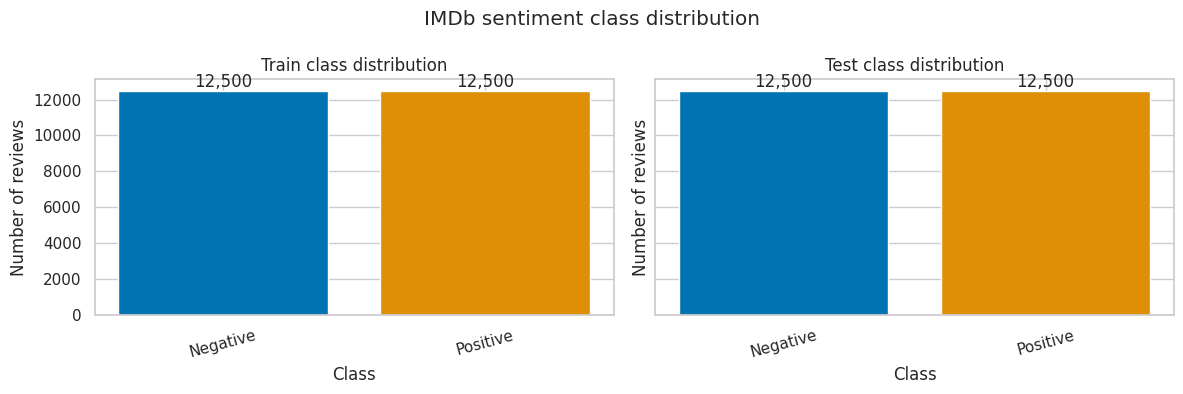

In [3]:
def label_name(value):
    if pd.isna(value):
        return "Missing label"
    return LABEL_NAMES.get(value, f"Invalid label ({value})")

def get_distribution(frame, split):
    counts = frame["label"].value_counts(dropna=False)
    return pd.DataFrame([
        {"Split": split, "Class": label_name(label), "Count": int(count),
         "Percentage": 100 * count / len(frame) if len(frame) else 0}
        for label, count in counts.items()
    ])

class_distribution = pd.concat([
    get_distribution(train_df, "Train"),
    get_distribution(test_df, "Test"),
    get_distribution(all_df, "Overall"),
], ignore_index=True)

for split in ["Train", "Test", "Overall"]:
    print()
    print(split)
    display(class_distribution.loc[
        class_distribution["Split"].eq(split), ["Class", "Count", "Percentage"]
    ].reset_index(drop=True).style.format({"Percentage": "{:.2f}%"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["Train", "Test"]):
    data = class_distribution[class_distribution["Split"].eq(split)]
    bars = ax.bar(data["Class"], data["Count"],
                  color=sns.color_palette("colorblind", n_colors=len(data)))
    ax.set_title(f"{split} class distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of reviews")
    ax.tick_params(axis="x", rotation=15)
    for bar, value in zip(bars, data["Count"]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{value:,}", ha="center", va="bottom")
fig.suptitle("IMDb sentiment class distribution")
plt.tight_layout()
plt.show()


### Giải thích

Bảng hiển thị số lượng và tỷ lệ từng nhãn. Hai biểu đồ giúp so sánh train với test; nhãn thiếu/không hợp lệ, nếu có, cũng được thể hiện.


## Task 3 — Document length

Tính số từ bằng whitespace tokenization, thống kê min/max/mean/median/std và vẽ histogram theo từng split.


,Reviews counted,Min,Max,Mean,Median,Standard deviation
Train,"25,000",10,"2,470",233.79,174.00,173.73
Test,"25,000",4,"2,278",228.53,172.00,168.88
Overall,"50,000",4,"2,470",231.16,173.00,171.34


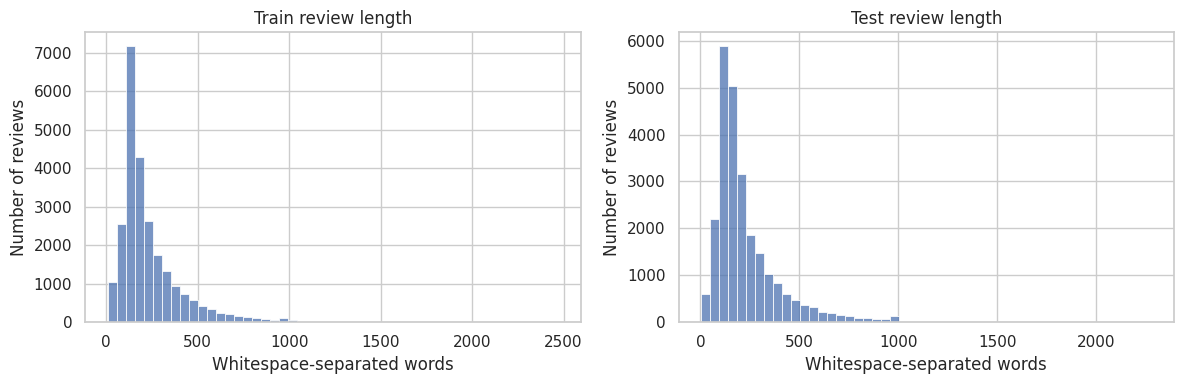

In [4]:
def word_count(text):
    if pd.isna(text):
        return np.nan
    return len(text.split())

train_df["document_length"] = train_df["text"].map(word_count)
test_df["document_length"] = test_df["text"].map(word_count)
all_df = pd.concat([train_df, test_df], ignore_index=True)

def describe_lengths(series):
    return pd.Series({
        "Reviews counted": series.count(),
        "Min": series.min(),
        "Max": series.max(),
        "Mean": series.mean(),
        "Median": series.median(),
        "Standard deviation": series.std(),
    })

length_table = pd.DataFrame({
    "Train": describe_lengths(train_df["document_length"]),
    "Test": describe_lengths(test_df["document_length"]),
    "Overall": describe_lengths(all_df["document_length"]),
}).T
display(length_table.style.format({
    "Reviews counted": "{:,.0f}", "Min": "{:,.0f}", "Max": "{:,.0f}",
    "Mean": "{:,.2f}", "Median": "{:,.2f}", "Standard deviation": "{:,.2f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, frame in zip(axes, ["Train", "Test"], [train_df, test_df]):
    sns.histplot(data=frame, x="document_length", bins=50, ax=ax)
    ax.set_title(f"{name} review length")
    ax.set_xlabel("Whitespace-separated words")
    ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()


### Giải thích

len(text.split()) được tính cho từng review. Missing text cho ra NaN nên không bị tính nhầm thành review có độ dài 0.


## Task 4 — Duplicate documents

Đếm exact duplicate trong từng split và toàn bộ dữ liệu; tìm review text xuất hiện ở cả train lẫn test. Chỉ cảnh báo, không xóa.


In [5]:
def duplicate_info(series):
    values = series.dropna()
    count = int(values.duplicated(keep="first").sum())
    return {
        "Rows checked": len(values),
        "Duplicate rows": count,
        "Duplicate (%)": 100 * count / len(values) if len(values) else 0,
    }

train_duplicates = duplicate_info(train_df["text"])
test_duplicates = duplicate_info(test_df["text"])
overall_duplicates = duplicate_info(pd.concat(
    [train_df["text"], test_df["text"]], ignore_index=True
))

train_text_set = set(train_df["text"].dropna())
test_text_set = set(test_df["text"].dropna())
shared_texts = train_text_set & test_text_set
test_rows_in_train = int(test_df["text"].dropna().isin(train_text_set).sum())
train_rows_in_test = int(train_df["text"].dropna().isin(test_text_set).sum())

duplicate_table = pd.DataFrame([
    {"Split": "Train", **train_duplicates},
    {"Split": "Test", **test_duplicates},
    {"Split": "Overall", **overall_duplicates},
])
display(duplicate_table.style.format({
    "Rows checked": "{:,.0f}", "Duplicate rows": "{:,.0f}",
    "Duplicate (%)": "{:.4f}%",
}))
print("Unique exact texts shared across splits:", len(shared_texts))
print("Test rows whose text is in train:", test_rows_in_train)
print("Train rows whose text is in test:", train_rows_in_test)
print("No data was removed.")


,Split,Rows checked,Duplicate rows,Duplicate (%)
0,Train,"25,000",96,0.3840%
1,Test,"25,000",199,0.7960%
2,Overall,"50,000",418,0.8360%


Unique exact texts shared across splits: 123
Test rows whose text is in train: 123
Train rows whose text is in test: 123
No data was removed.


### Giải thích

Duplicate là text trùng chính xác; tỷ lệ tính trên số text không missing. Cross-split overlap được báo riêng để nhận diện review trùng giữa train/test.


## Task 5 — Missing text

Kiểm tra riêng NaN/None, empty string và whitespace-only string; báo count và percentage theo split.


In [6]:
def text_quality(frame, split):
    text = frame["text"]
    missing = text.isna()
    empty = text.notna() & text.eq("")
    whitespace = text.notna() & text.ne("") & text.str.fullmatch(r"\s*", na=False)
    total = len(frame)
    return {
        "Split": split, "Rows": total,
        "Missing": int(missing.sum()), "Missing (%)": 100*missing.sum()/total,
        "Empty": int(empty.sum()), "Empty (%)": 100*empty.sum()/total,
        "Whitespace-only": int(whitespace.sum()),
        "Whitespace-only (%)": 100*whitespace.sum()/total,
    }

text_quality_table = pd.DataFrame([
    text_quality(train_df, "Train"),
    text_quality(test_df, "Test"),
    text_quality(all_df, "Overall"),
])
display(text_quality_table.style.format({
    "Rows": "{:,.0f}", "Missing": "{:,.0f}", "Missing (%)": "{:.4f}%",
    "Empty": "{:,.0f}", "Empty (%)": "{:.4f}%",
    "Whitespace-only": "{:,.0f}", "Whitespace-only (%)": "{:.4f}%",
}))


,Split,Rows,Missing,Missing (%),Empty,Empty (%),Whitespace-only,Whitespace-only (%)
0,Train,"25,000",0,0.0000%,0,0.0000%,0,0.0000%
1,Test,"25,000",0,0.0000%,0,0.0000%,0,0.0000%
2,Overall,"50,000",0,0.0000%,0,0.0000%,0,0.0000%


Technical fix: the whitespace-only check now matches whitespace characters (spaces, tabs, and line breaks), rather than the letter s. The notebook also activates Jupyter inline plotting so figures are included in saved outputs.


### Giải thích

Missing, empty và whitespace-only là các trường hợp khác nhau nên được đếm riêng, không tự điền hay loại bỏ text.


## Task 6 — Missing labels and invalid labels

Missing label là NaN/None; invalid label là giá trị khác 0 và 1. Chỉ kiểm tra, không sửa nhãn.


In [7]:
def label_quality(frame, split):
    labels = frame["label"]
    missing = labels.isna()
    invalid = labels.notna() & ~labels.isin([0, 1])
    total = len(frame)
    return {
        "Split": split, "Rows": total,
        "Missing labels": int(missing.sum()),
        "Missing (%)": 100*missing.sum()/total,
        "Invalid labels": int(invalid.sum()),
        "Invalid (%)": 100*invalid.sum()/total,
        "Invalid values": sorted(labels[invalid].unique().tolist(), key=str),
    }

label_quality_table = pd.DataFrame([
    label_quality(train_df, "Train"),
    label_quality(test_df, "Test"),
    label_quality(all_df, "Overall"),
])
display(label_quality_table.style.format({
    "Rows": "{:,.0f}", "Missing labels": "{:,.0f}", "Missing (%)": "{:.4f}%",
    "Invalid labels": "{:,.0f}", "Invalid (%)": "{:.4f}%",
}))


,Split,Rows,Missing labels,Missing (%),Invalid labels,Invalid (%),Invalid values
0,Train,"25,000",0,0.0000%,0,0.0000%,[]
1,Test,"25,000",0,0.0000%,0,0.0000%,[]
2,Overall,"50,000",0,0.0000%,0,0.0000%,[]


### Giải thích

Cell phân biệt nhãn bị thiếu với nhãn có giá trị nhưng ngoài tập {0, 1}; không thay đổi label.


## Task 7 — Summary

In [8]:
def binary_counts(frame):
    return frame["label"].value_counts().reindex([0, 1], fill_value=0)

summary = pd.DataFrame([
    {"Metric": "Samples", "Train": len(train_df), "Test": len(test_df),
     "Overall": len(all_df)},
    {"Metric": "Observed classes",
     "Train": train_df["label"].dropna().nunique(),
     "Test": test_df["label"].dropna().nunique(),
     "Overall": all_df["label"].dropna().nunique()},
    {"Metric": "Exact duplicate rows",
     "Train": train_duplicates["Duplicate rows"],
     "Test": test_duplicates["Duplicate rows"],
     "Overall": overall_duplicates["Duplicate rows"]},
    {"Metric": "Missing text",
     "Train": int(train_df["text"].isna().sum()),
     "Test": int(test_df["text"].isna().sum()),
     "Overall": int(all_df["text"].isna().sum())},
    {"Metric": "Empty text",
     "Train": int((train_df["text"].notna() & train_df["text"].eq("")).sum()),
     "Test": int((test_df["text"].notna() & test_df["text"].eq("")).sum()),
     "Overall": int((all_df["text"].notna() & all_df["text"].eq("")).sum())},
    {"Metric": "Whitespace-only text",
     "Train": int((train_df["text"].notna() & train_df["text"].ne("") & train_df["text"].str.fullmatch(r"\s*", na=False)).sum()),
     "Test": int((test_df["text"].notna() & test_df["text"].ne("") & test_df["text"].str.fullmatch(r"\s*", na=False)).sum()),
     "Overall": int((all_df["text"].notna() & all_df["text"].ne("") & all_df["text"].str.fullmatch(r"\s*", na=False)).sum())},
    {"Metric": "Missing labels",
     "Train": int(train_df["label"].isna().sum()),
     "Test": int(test_df["label"].isna().sum()),
     "Overall": int(all_df["label"].isna().sum())},
    {"Metric": "Invalid labels",
     "Train": int((train_df["label"].notna() & ~train_df["label"].isin([0, 1])).sum()),
     "Test": int((test_df["label"].notna() & ~test_df["label"].isin([0, 1])).sum()),
     "Overall": int((all_df["label"].notna() & ~all_df["label"].isin([0, 1])).sum())},
    {"Metric": "Unique texts shared between splits",
     "Train": len(shared_texts), "Test": len(shared_texts),
     "Overall": len(shared_texts)},
])
display(summary)

imbalance_rows = []
for name, frame in [("Train", train_df), ("Test", test_df), ("Overall", all_df)]:
    counts = binary_counts(frame)
    ratio = counts.max() / counts.min() if counts.min() else np.nan
    imbalance_rows.append({
        "Split": name, "Negative": int(counts.loc[0]),
        "Positive": int(counts.loc[1]), "Majority/minority ratio": ratio,
        "Counts unequal": bool(counts.loc[0] != counts.loc[1]),
    })
imbalance_table = pd.DataFrame(imbalance_rows)
display(imbalance_table.style.format({
    "Negative": "{:,.0f}", "Positive": "{:,.0f}",
    "Majority/minority ratio": "{:.4f}",
}))

counts = binary_counts(all_df)
if counts.loc[0] == counts.loc[1]:
    conclusion = "Overall counts for Negative and Positive are equal: no class-count imbalance by this check."
else:
    conclusion = "Overall counts for Negative and Positive are unequal: a class-count difference is present."
display(Markdown(
    "### Class distribution observation\n\n" + conclusion +
    "\n\nDuplicate and missing-value counts are separate data-quality issues, not class imbalance."
))


,Metric,Train,Test,Overall
0,Samples,25000,25000,50000
1,Observed classes,2,2,2
2,Exact duplicate rows,96,199,418
3,Missing text,0,0,0
4,Empty text,0,0,0
5,Whitespace-only text,0,0,0
6,Missing labels,0,0,0
7,Invalid labels,0,0,0
8,Unique texts shared between splits,123,123,123


,Split,Negative,Positive,Majority/minority ratio,Counts unequal
0,Train,"12,500","12,500",1.0000,False
1,Test,"12,500","12,500",1.0000,False
2,Overall,"25,000","25,000",1.0000,False


### Class distribution observation

Overall counts for Negative and Positive are equal: no class-count imbalance by this check.

Duplicate and missing-value counts are separate data-quality issues, not class imbalance.

### Giải thích

Bảng tổng hợp các phép kiểm tra. Imbalance được xác định trực tiếp bằng so sánh số lớp 0 và 1; tỷ lệ majority/minority được in ra. Duplicate/missing là kiểm tra chất lượng dữ liệu riêng.

## Câu hỏi gợi ý tự nhận xét

1. Dataset có imbalance không? Vì sao? Dựa vào count, percentage và majority/minority ratio.
2. Phân phối lớp của train và test có giống nhau không?
3. Mean và median độ dài review khác nhau thế nào? Histogram cho thấy gì?
4. Có duplicate trong split hoặc giữa train/test không?
5. Có missing/empty text hoặc missing/invalid label không?
6. Vì sao imbalance khác duplicate và missing values?

Chỉ sử dụng kết quả thực tế từ các cell trên. Experiment 1 không train classifier.


# 12. Data Leakage

Mục này tiếp nối Dataset Inspection. Dùng toàn bộ dữ liệu có nhãn trong biến df; không tải dataset lại và không dùng split unsupervised. Nếu notebook hiện tại chưa có df nhưng đã có train_df/test_df từ Experiment 1, cell sẽ ghép hai DataFrame đó làm fallback.

Quy trình: kiểm tra dữ liệu → chia train/validation/test → fit TF-IDF trên train → transform validation/test. Không huấn luyện classifier ở mục này.


## 12.1 Chuẩn bị dữ liệu và Train / Validation / Test split

Giữ lại text, label và tạo sample ID theo vị trí dòng để kiểm tra overlap. Chia 60%/20%/20%, stratify theo label và dùng random_state=2026 cho mỗi lần chia.


In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Dùng df có sẵn; fallback này không tải lại dataset.
if "df" in globals():
    source_df = df
elif "train_df" in globals() and "test_df" in globals():
    source_df = pd.concat(
        [train_df[["text", "label"]], test_df[["text", "label"]]],
        ignore_index=True,
    )
else:
    raise NameError("Cần có df hoặc train_df/test_df từ Experiment 1.")

# Bản làm việc chỉ gồm hai cột cần dùng, không sửa df gốc.
data = source_df[["text", "label"]].reset_index(drop=True).copy()
sample_ids = np.arange(len(data))

missing_text = data["text"].isna()
missing_label = data["label"].isna()
empty_text = data["text"].notna() & data["text"].astype(str).str.strip().eq("")
invalid_labels = data["label"].notna() & ~data["label"].isin([0, 1])

print("Labeled samples:", len(data))
print("Missing text:", int(missing_text.sum()))
print("Empty/whitespace-only text:", int(empty_text.sum()))
print("Missing labels:", int(missing_label.sum()))
print("Invalid labels:", int(invalid_labels.sum()))

if missing_text.any() or empty_text.any() or missing_label.any() or invalid_labels.any():
    raise ValueError(
        "Có text/label cần kiểm tra trước khi split. "
        "Không có sample nào tự động bị xóa hoặc sửa."
    )

# Split lần 1: 60% train và 40% tạm thời.
train_ids, remainder_ids = train_test_split(
    sample_ids,
    test_size=0.40,
    random_state=2026,
    stratify=data["label"],
)

# Split lần 2: chia 40% còn lại thành validation 20% và test 20%.
val_ids, test_ids = train_test_split(
    remainder_ids,
    test_size=0.50,
    random_state=2026,
    stratify=data.iloc[remainder_ids]["label"],
)

train_data = data.iloc[train_ids].copy()
val_data = data.iloc[val_ids].copy()
test_data = data.iloc[test_ids].copy()

print("\nSplit sizes:")
print(f"Train: {len(train_data):,} ({len(train_data)/len(data):.1%})")
print(f"Validation: {len(val_data):,} ({len(val_data)/len(data):.1%})")
print(f"Test: {len(test_data):,} ({len(test_data)/len(data):.1%})")
print("Total after split:", len(train_data) + len(val_data) + len(test_data))
print("Original total:", len(data))

def show_class_percentages(frame, split_name):
    counts = frame["label"].value_counts().reindex([0, 1], fill_value=0)
    return pd.DataFrame({
        "Split": split_name,
        "Class": ["Negative (0)", "Positive (1)"],
        "Count": [int(counts.loc[0]), int(counts.loc[1])],
        "Percentage": [
            100 * counts.loc[0] / len(frame),
            100 * counts.loc[1] / len(frame),
        ],
    })

split_class_table = pd.concat([
    show_class_percentages(train_data, "Train"),
    show_class_percentages(val_data, "Validation"),
    show_class_percentages(test_data, "Test"),
], ignore_index=True)
display(split_class_table.style.format({"Percentage": "{:.2f}%"}))


Labeled samples: 50000
Missing text: 0
Empty/whitespace-only text: 0
Missing labels: 0
Invalid labels: 0



Split sizes:
Train: 30,000 (60.0%)
Validation: 10,000 (20.0%)
Test: 10,000 (20.0%)
Total after split: 50000
Original total: 50000


,Split,Class,Count,Percentage
0,Train,Negative (0),15000,50.00%
1,Train,Positive (1),15000,50.00%
2,Validation,Negative (0),5000,50.00%
3,Validation,Positive (1),5000,50.00%
4,Test,Negative (0),5000,50.00%
5,Test,Positive (1),5000,50.00%


## 12.2 Kiểm tra sample index và duplicate text giữa splits

Sample ID là vị trí dòng trong bản dữ liệu làm việc. Kiểm tra ID overlap và exact duplicate text giữa từng cặp split. Duplicate chỉ được cảnh báo, không tự động xóa.


In [10]:
id_sets = {
    "train": set(train_ids.tolist()),
    "validation": set(val_ids.tolist()),
    "test": set(test_ids.tolist()),
}

assert len(train_data) + len(val_data) + len(test_data) == len(data)
assert id_sets["train"].isdisjoint(id_sets["validation"])
assert id_sets["train"].isdisjoint(id_sets["test"])
assert id_sets["validation"].isdisjoint(id_sets["test"])
assert len(set.union(*id_sets.values())) == len(data)

print("Sample count preserved:", len(data))
print("Train/validation/test sample IDs are pairwise disjoint: True")

text_sets = {
    "train": set(train_data["text"]),
    "validation": set(val_data["text"]),
    "test": set(test_data["text"]),
}
split_names = ["train", "validation", "test"]
duplicate_overlap_rows = []

for i, split_a in enumerate(split_names):
    for split_b in split_names[i + 1:]:
        shared_texts = text_sets[split_a] & text_sets[split_b]
        duplicate_overlap_rows.append({
            "Split A": split_a,
            "Split B": split_b,
            "Unique exact texts shared": len(shared_texts),
        })
        if shared_texts:
            print(
                f"WARNING: {len(shared_texts)} exact review texts occur in "
                f"both {split_a} and {split_b}."
            )

duplicate_overlap_table = pd.DataFrame(duplicate_overlap_rows)
display(duplicate_overlap_table)

if duplicate_overlap_table["Unique exact texts shared"].sum() == 0:
    print("No exact duplicate text was found across the three splits.")
else:
    print(
        "Leakage risk: an identical review may occur in multiple splits. "
        "For a future split, consider keeping identical-text groups together "
        "(for example, a group-aware stratified split) after inspecting labels. "
        "No review was removed in this notebook."
    )


Sample count preserved: 50000
Train/validation/test sample IDs are pairwise disjoint: True


,Split A,Split B,Unique exact texts shared
0,train,validation,93
1,train,test,110
2,validation,test,21


Leakage risk: an identical review may occur in multiple splits. For a future split, consider keeping identical-text groups together (for example, a group-aware stratified split) after inspecting labels. No review was removed in this notebook.


## 12.3 Preprocessing: fit TF-IDF on train only

TfidfVectorizer learns its vocabulary and IDF values using train text only. Validation and test are transformed with that already-fitted vectorizer; they do not contribute features or IDF statistics.


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    lowercase=True,
)

# Chỉ train được dùng cho fit; validation/test chỉ transform.
X_train = vectorizer.fit_transform(train_data["text"])
X_val = vectorizer.transform(val_data["text"])
X_test = vectorizer.transform(test_data["text"])

y_train = train_data["label"].to_numpy()
y_val = val_data["label"].to_numpy()
y_test = test_data["label"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)
print("Actual vocabulary size:", len(vectorizer.vocabulary_))


X_train shape: (30000, 10000)
X_val shape: (10000, 10000)
X_test shape: (10000, 10000)
Actual vocabulary size: 10000


## 12.4 Data Leakage Verification

Kiểm tra lại sample count, index disjointness, missing values và nguồn học vocabulary/IDF. Với smooth_idf mặc định, IDF của mỗi feature được đối chiếu với document frequency trong X_train.


In [12]:
# Xác nhận kích thước split, không overlap sample IDs và không còn missing fields.
assert X_train.shape[0] == len(train_data) == len(y_train)
assert X_val.shape[0] == len(val_data) == len(y_val)
assert X_test.shape[0] == len(test_data) == len(y_test)
assert len(train_data) + len(val_data) + len(test_data) == len(data)
assert id_sets["train"].isdisjoint(id_sets["validation"])
assert id_sets["train"].isdisjoint(id_sets["test"])
assert id_sets["validation"].isdisjoint(id_sets["test"])
assert not data["text"].isna().any()
assert not data["label"].isna().any()
assert data["label"].isin([0, 1]).all()

# Mọi cột trong vocabulary xuất hiện trong train matrix.
train_document_frequency = np.asarray(X_train.getnnz(axis=0)).ravel()
assert np.all(train_document_frequency > 0)

# TfidfVectorizer smooth_idf=True mặc định:
# idf(t) = log((1 + N_train) / (1 + df_train(t))) + 1
expected_train_idf = np.log(
    (1 + X_train.shape[0]) / (1 + train_document_frequency)
) + 1
assert np.allclose(vectorizer.idf_, expected_train_idf)

print("All leakage checks passed.")
print("Vocabulary learned from train only:", len(vectorizer.vocabulary_))
print("IDF verified against train document frequencies only.")
print("Validation/test were transformed, not used to fit TF-IDF.")


All leakage checks passed.
Vocabulary learned from train only: 10000
IDF verified against train document frequencies only.
Validation/test were transformed, not used to fit TF-IDF.


## Tóm tắt kỹ thuật và câu hỏi tự trả lời

Pipeline đúng:

**Data có nhãn → chia train/validation/test → fit TF-IDF trên train → transform validation/test**

TF-IDF học vocabulary và IDF từ **training set בלבד**. Nếu fit trên toàn bộ dữ liệu trước khi split, thống kê từ validation/test đã ảnh hưởng tới vocabulary và IDF; khi đó thông tin của tập đánh giá lọt vào bước xây dựng features trước khi đánh giá.

Câu hỏi để bạn tự trả lời: **“Vì sao đây là data leakage?”**

Gợi ý suy nghĩ:
- Những thông tin nào của validation/test được vectorizer nhìn thấy khi fit trên toàn bộ dataset?
- Vì sao validation/test cần mô phỏng dữ liệu chưa thấy trong quá trình học?
- Điều gì có thể xảy ra với độ tin cậy của kết quả đánh giá nếu preprocessing đã dùng thống kê từ test?
- Duplicate text giữa các splits khác với việc fit vocabulary/IDF trên toàn bộ dữ liệu ở điểm nào?


# 13. Core Implementation

Pipeline: TF-IDF đã fit trên Train → Logistic Regression → dự đoán và đánh giá trên Validation. Test không dùng ở mục này.


## 13.1 Initialize Classifier

In [13]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000, random_state=2026)


## 13.2 Model Training

Chỉ fit classifier trên Train. Training time không gồm tải dữ liệu hay TF-IDF.


In [14]:
from time import perf_counter
lr_start_time = perf_counter()
lr_model.fit(X_train, y_train)
lr_training_time = perf_counter() - lr_start_time
print(f"Logistic Regression training time: {lr_training_time:.4f} seconds")


Logistic Regression training time: 0.9794 seconds


## 13.3 Prediction

Dự đoán trên Validation và hiển thị tối đa năm review cùng nhãn thật, nhãn dự đoán và xác suất Positive.


In [15]:
y_val_pred = lr_model.predict(X_val)
y_val_positive_probability = lr_model.predict_proba(X_val)[:, list(lr_model.classes_).index(1)]
prediction_preview = pd.DataFrame({
    "Text": [str(t)[:150] + ("..." if len(str(t)) > 150 else "") for t in val_data["text"].iloc[:5]],
    "True Label": y_val[:5],
    "Predicted Label": y_val_pred[:5],
    "Positive Probability": y_val_positive_probability[:5],
})
display(prediction_preview.style.format({"Positive Probability": "{:.4f}"}))


,Text,True Label,Predicted Label,Positive Probability
0,"Every time I watch this movie blood comes gushing out of my eyes. Yes, you read that correctly: I've watched this wretched, foul thing more than once....",0,0,0.0385
1,"I watched this film during a special advanced preview in Reading, Berkshire.The two main characters, Michael and Rory strike up a friendsh...",1,1,0.8960
2,All you could ever hope for if your a Jackass fan.As always Knoxville & his crew risk life & limb just for our viewing entertainment. If you are fan o...,1,1,0.8387
3,"This movie was two and a quarter excruciating hours. Someone please tell me what the point was?I mean, I understand the historical setting...",0,0,0.0488
4,"No blood, no sex (though it oozes passion), no special effects, but just one of those pearls that comes across your movie screen when you're not reall...",1,1,0.7583


## 13.4 Evaluation

Metrics được tính trên Validation; Positive label là 1.


In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
lr_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, average="binary", pos_label=1, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, average="binary", pos_label=1, zero_division=0),
    "F1": f1_score(y_val, y_val_pred, average="binary", pos_label=1, zero_division=0),
}
print({k: f"{v:.4f}" for k, v in lr_metrics.items()})


{'Accuracy': '0.8868', 'Precision': '0.8801', 'Recall': '0.8956', 'F1': '0.8878'}


## 13.5 Understanding Logistic Regression

Logistic Regression tính z = wᵀx + b và P(y=1|x) = sigmoid(z) = 1/(1+e⁻ᶻ). x là TF-IDF vector; w và b được học từ Train; z là logit.


In [17]:
sample_x = X_val[0]
sample_logit = float(lr_model.decision_function(sample_x)[0])
if sample_logit >= 0:
    sample_sigmoid = 1 / (1 + np.exp(-sample_logit))
else:
    exp_logit = np.exp(sample_logit)
    sample_sigmoid = exp_logit / (1 + exp_logit)
sample_probability = float(lr_model.predict_proba(sample_x)[0, list(lr_model.classes_).index(1)])
print("Logit:", sample_logit)
print("Manual sigmoid:", sample_sigmoid)
print("predict_proba:", sample_probability)
print("Probabilities match:", np.isclose(sample_sigmoid, sample_probability))
print("Prediction at threshold 0.5:", int(sample_sigmoid >= 0.5))
assert np.isclose(sample_sigmoid, sample_probability)


Logit: -3.218857464935261
Manual sigmoid: 0.03846221745889495
predict_proba: 0.03846221745889495
Probabilities match: True
Prediction at threshold 0.5: 0


# 14. Experiment 2 — Baseline

Tổng hợp baseline từ model của mục 13; không huấn luyện lại hoặc fit lại TF-IDF.


## 14.1 Baseline Statistics

In [18]:
baseline_vocabulary_size = len(vectorizer.vocabulary_)
baseline_row = {
    "Model": "TF-IDF + Logistic Regression",
    "Representation": "TF-IDF Unigram",
    "Classifier": "Logistic Regression",
    "Training Time (s)": lr_training_time,
    "Vocabulary Size": baseline_vocabulary_size,
    **lr_metrics,
}
baseline_table = pd.DataFrame([baseline_row])
display(baseline_table.style.format({
    "Training Time (s)": "{:.4f}", "Vocabulary Size": "{:.0f}",
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
}))


,Model,Representation,Classifier,Training Time (s),Vocabulary Size,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,TF-IDF Unigram,Logistic Regression,0.9794,10000,0.8868,0.8801,0.8956,0.8878


## 14.2 Baseline Results

Các số liệu được lấy trực tiếp từ quá trình train và dự đoán ở mục 13.


## 14.3 Save Baseline

Hàm dưới lưu vào results.csv trong thư mục làm việc hiện tại, cập nhật dòng trùng tên và giữ các experiment khác.


In [19]:
from pathlib import Path

def find_lab_directory():
    current = Path.cwd()
    candidates = [current, current/"Lab4", current/"lab04", current/"NLP"/"Lab4",
                  current/"NLP"/"lab04", current.parent/"Lab4", current.parent/"lab04"]
    for candidate in candidates:
        if (candidate/"classification.ipynb").exists():
            return candidate
    return current

LAB_DIRECTORY = find_lab_directory()
RESULTS_PATH = LAB_DIRECTORY / "results.csv"

def update_results_csv(new_rows, path=RESULTS_PATH):
    new_rows = pd.DataFrame(new_rows).copy()
    if "Split" not in new_rows:
        new_rows["Split"] = "Validation"
    if path.exists():
        old_rows = pd.read_csv(path)
        if "Model" not in old_rows.columns:
            raise ValueError("results.csv must have a Model column; existing file was not changed.")
        if "Split" not in old_rows:
            old_rows["Split"] = "Validation"
        old_rows["Split"] = old_rows["Split"].fillna("Validation")
        new_rows["Split"] = new_rows["Split"].fillna("Validation")
        replace_keys = set(zip(new_rows["Model"], new_rows["Split"]))
        old_keys = list(zip(old_rows["Model"], old_rows["Split"]))
        old_rows = old_rows.loc[[key not in replace_keys for key in old_keys]]
        combined = pd.concat([old_rows, new_rows], ignore_index=True, sort=False)
    else:
        combined = new_rows
    combined.to_csv(path, index=False)
    return combined

results_table = update_results_csv([baseline_row])
print("Saved:", RESULTS_PATH.resolve())
display(results_table)


Saved: /home/nguyenducthang/NLP/Lab4/results.csv


,Model,Representation,Classifier,Training Time (s),Vocabulary Size,Accuracy,Precision,Recall,F1,Split,Word2Vec Training Time (s),Classifier Training Time (s),Total Training Time (s),Experiment,Features,Unigram Features,Bigram Features
0,Experiment 5 — TF-IDF Unigram + Logistic Regression,NaN,NaN,1.011974,10000.0,NaN,NaN,NaN,0.887787,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram,10000.0,0.0
1,Experiment 5 — TF-IDF Unigram + Bigram + Logistic Regression,NaN,NaN,0.530805,10000.0,NaN,NaN,NaN,0.894038,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram + Bigram,4388.0,5612.0
2,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,256.105780,50914.0,0.8695,0.867223,0.8726,0.869903,Validation,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TF-IDF + Linear SVM,TF-IDF,Linear SVM,1.325419,10000.0,0.8856,0.880576,0.8922,0.886350,Validation,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TF-IDF + Logistic Regression,NaN,NaN,NaN,NaN,0.8885,0.877845,0.9026,0.890050,Test,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,TF-IDF + Logistic Regression,TF-IDF Unigram,Logistic Regression,0.979434,10000.0,0.8868,0.880110,0.8956,0.887787,Validation,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 15. Experiment 3 — Representation Comparison

So sánh ba mô hình trên cùng Validation. Word2Vec chỉ được huấn luyện bằng Train reviews.


## 15.1 Model A — TF-IDF + Logistic Regression

Tái sử dụng baseline; không train lại.


In [20]:
model_a_metrics = lr_metrics.copy()
model_a_training_time = lr_training_time
model_a_vocabulary_size = baseline_vocabulary_size


## 15.2 Model B — Average Word2Vec + Logistic Regression

Tokenize các split cùng một cách; chỉ Train được dùng để học Word2Vec. Thời gian Word2Vec không bao gồm tokenization.


In [21]:
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

train_tokens = [simple_preprocess(str(t), deacc=False) for t in train_data["text"]]
val_tokens = [simple_preprocess(str(t), deacc=False) for t in val_data["text"]]
test_tokens = [simple_preprocess(str(t), deacc=False) for t in test_data["text"]]

w2v_start = perf_counter()
w2v_model = Word2Vec(
    sentences=train_tokens, vector_size=100, window=5, min_count=2,
    workers=1, sg=1, seed=2026, epochs=10,
)
w2v_training_time = perf_counter() - w2v_start
w2v_vocabulary_size = len(w2v_model.wv)
print("Word2Vec vocabulary size:", w2v_vocabulary_size)
print(f"Word2Vec training time: {w2v_training_time:.4f} seconds")


Word2Vec vocabulary size: 50914
Word2Vec training time: 251.0241 seconds


### Average Word Embeddings

Review vector là trung bình các token vectors có trong vocabulary; nếu không có token hợp lệ thì trả zero vector 100 chiều.


In [22]:
def average_word_vectors(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    if not vectors:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0).astype(np.float32)

X_train_w2v = np.vstack([average_word_vectors(t, w2v_model) for t in train_tokens])
X_val_w2v = np.vstack([average_word_vectors(t, w2v_model) for t in val_tokens])
X_test_w2v = np.vstack([average_word_vectors(t, w2v_model) for t in test_tokens])
print("X_train_w2v:", X_train_w2v.shape)
print("X_val_w2v:", X_val_w2v.shape)
print("X_test_w2v:", X_test_w2v.shape)


X_train_w2v: (30000, 100)
X_val_w2v: (10000, 100)
X_test_w2v: (10000, 100)


### Logistic Regression trên Average Word2Vec

Thời gian Model B được tách thành thời gian fit Word2Vec và Logistic Regression; tổng bằng tổng hai thời gian.


In [23]:
lr_w2v_model = LogisticRegression(max_iter=1000, random_state=2026)
w2v_lr_start = perf_counter()
lr_w2v_model.fit(X_train_w2v, y_train)
w2v_lr_training_time = perf_counter() - w2v_lr_start

y_val_pred_w2v = lr_w2v_model.predict(X_val_w2v)
model_b_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_w2v),
    "Precision": precision_score(y_val, y_val_pred_w2v, average="binary", pos_label=1, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_w2v, average="binary", pos_label=1, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_w2v, average="binary", pos_label=1, zero_division=0),
}
model_b_total_time = w2v_training_time + w2v_lr_training_time
print(f"Word2Vec: {w2v_training_time:.4f}s; classifier: {w2v_lr_training_time:.4f}s; total: {model_b_total_time:.4f}s")


Word2Vec: 251.0241s; classifier: 0.6431s; total: 251.6672s


## 15.3 Model C — TF-IDF + Linear SVM

Dùng lại TF-IDF matrices; chỉ fit SVM trên Train.


In [24]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC(random_state=2026, max_iter=5000)
svm_start = perf_counter()
svm_model.fit(X_train, y_train)
svm_training_time = perf_counter() - svm_start

y_val_pred_svm = svm_model.predict(X_val)
model_c_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_svm),
    "Precision": precision_score(y_val, y_val_pred_svm, average="binary", pos_label=1, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_svm, average="binary", pos_label=1, zero_division=0),
    "F1": f1_score(y_val, y_val_pred_svm, average="binary", pos_label=1, zero_division=0),
}
print(f"Linear SVM training time: {svm_training_time:.4f} seconds")


Linear SVM training time: 2.4047 seconds


## 15.4 Comparison Table

In [25]:
comparison_rows = [
    {
        "Model": "TF-IDF + Logistic Regression", "Representation": "TF-IDF",
        "Classifier": "Logistic Regression", "Training Time (s)": model_a_training_time,
        "Word2Vec Training Time (s)": np.nan, "Classifier Training Time (s)": model_a_training_time,
        "Total Training Time (s)": model_a_training_time, "Vocabulary Size": model_a_vocabulary_size,
        **model_a_metrics,
    },
    {
        "Model": "Average Word2Vec + Logistic Regression", "Representation": "Average Word2Vec",
        "Classifier": "Logistic Regression", "Training Time (s)": model_b_total_time,
        "Word2Vec Training Time (s)": w2v_training_time, "Classifier Training Time (s)": w2v_lr_training_time,
        "Total Training Time (s)": model_b_total_time, "Vocabulary Size": w2v_vocabulary_size,
        **model_b_metrics,
    },
    {
        "Model": "TF-IDF + Linear SVM", "Representation": "TF-IDF",
        "Classifier": "Linear SVM", "Training Time (s)": svm_training_time,
        "Word2Vec Training Time (s)": np.nan, "Classifier Training Time (s)": svm_training_time,
        "Total Training Time (s)": svm_training_time, "Vocabulary Size": model_a_vocabulary_size,
        **model_c_metrics,
    },
]
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.style.format({
    "Training Time (s)": "{:.4f}", "Word2Vec Training Time (s)": "{:.4f}",
    "Classifier Training Time (s)": "{:.4f}", "Total Training Time (s)": "{:.4f}",
    "Vocabulary Size": "{:.0f}", "Accuracy": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}",
}, na_rep="—"))
results_table = update_results_csv(comparison_table)
display(results_table)


,Model,Representation,Classifier,Training Time (s),Word2Vec Training Time (s),Classifier Training Time (s),Total Training Time (s),Vocabulary Size,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,0.9794,—,0.9794,0.9794,10000,0.8868,0.8801,0.8956,0.8878
1,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,251.6672,251.0241,0.6431,251.6672,50914,0.8695,0.8672,0.8726,0.8699
2,TF-IDF + Linear SVM,TF-IDF,Linear SVM,2.4047,—,2.4047,2.4047,10000,0.8856,0.8806,0.8922,0.8864


,Model,Representation,Classifier,Training Time (s),Vocabulary Size,Accuracy,Precision,Recall,F1,Split,Word2Vec Training Time (s),Classifier Training Time (s),Total Training Time (s),Experiment,Features,Unigram Features,Bigram Features
0,Experiment 5 — TF-IDF Unigram + Logistic Regression,NaN,NaN,1.011974,10000.0,NaN,NaN,NaN,0.887787,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram,10000.0,0.0
1,Experiment 5 — TF-IDF Unigram + Bigram + Logistic Regression,NaN,NaN,0.530805,10000.0,NaN,NaN,NaN,0.894038,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram + Bigram,4388.0,5612.0
2,TF-IDF + Logistic Regression,NaN,NaN,NaN,NaN,0.8885,0.877845,0.9026,0.890050,Test,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,0.979434,10000.0,0.8868,0.880110,0.8956,0.887787,Validation,NaN,0.979434,0.979434,NaN,NaN,NaN,NaN
4,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,251.667164,50914.0,0.8695,0.867223,0.8726,0.869903,Validation,251.024106,0.643059,251.667164,NaN,NaN,NaN,NaN
5,TF-IDF + Linear SVM,TF-IDF,Linear SVM,2.404734,10000.0,0.8856,0.880576,0.8922,0.886350,Validation,NaN,2.404734,2.404734,NaN,NaN,NaN,NaN


## 15.5 Visualization

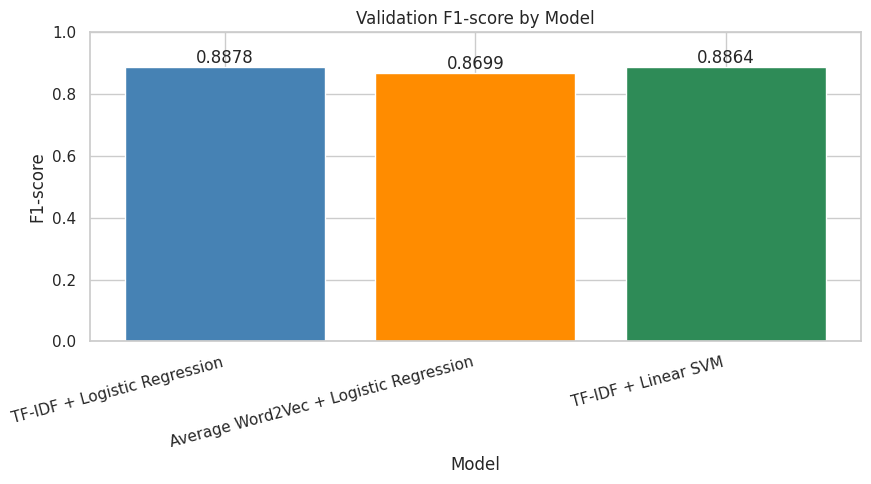

In [26]:
plt.figure(figsize=(9, 5))
bars = plt.bar(comparison_table["Model"], comparison_table["F1"], color=["steelblue", "darkorange", "seagreen"])
plt.title("Validation F1-score by Model")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
for bar, score in zip(bars, comparison_table["F1"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{score:.4f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


# 16. Representation Analysis — Evidence Preparation

Bảng dưới là đặc tính kỹ thuật để sinh viên tự phân tích; không viết kết luận thay sinh viên.

| Characteristic | TF-IDF | Average Word2Vec |
|---|---|---|
| Representation | Sparse | Dense |
| Information | Lexical | Statistical semantic patterns |
| Term importance | IDF weights retained | May be diluted by averaging |
| Word order | Not preserved with unigram | Not preserved by averaging |
| Context-dependent | No | No |
| Main limitation | Limited semantic matching | Averaging loses order and token-level information |


In [27]:
evidence_table = comparison_table[
    comparison_table["Model"].isin([
        "TF-IDF + Logistic Regression",
        "Average Word2Vec + Logistic Regression",
    ])
][["Model", "Accuracy", "Precision", "Recall", "F1", "Vocabulary Size", "Training Time (s)"]]
display(evidence_table.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1": "{:.4f}", "Vocabulary Size": "{:.0f}", "Training Time (s)": "{:.4f}",
}))


,Model,Accuracy,Precision,Recall,F1,Vocabulary Size,Training Time (s)
0,TF-IDF + Logistic Regression,0.8868,0.8801,0.8956,0.8878,10000,0.9794
1,Average Word2Vec + Logistic Regression,0.8695,0.8672,0.8726,0.8699,50914,251.6672


# 17. Experiment 4 — Word Order

## 17.1 Average Word2Vec

Tokenize bằng cùng simple_preprocess; in token có trong vocabulary và OOV, sau đó tính cosine similarity.


In [28]:
s1, s2 = "this movie is good", "this movie is not good"
word_order_sentences = [s1, s2]
word_order_tokens = [simple_preprocess(s, deacc=False) for s in word_order_sentences]
for sentence, tokens in zip(word_order_sentences, word_order_tokens):
    known = [t for t in tokens if t in w2v_model.wv]
    oov = [t for t in tokens if t not in w2v_model.wv]
    print(sentence)
    print("In vocabulary:", known)
    print("OOV:", oov if oov else "None")

word_order_vectors = np.vstack([average_word_vectors(t, w2v_model) for t in word_order_tokens])
norm_product = np.linalg.norm(word_order_vectors[0]) * np.linalg.norm(word_order_vectors[1])
if norm_product == 0:
    word_order_cosine = None
    print("Cosine similarity undefined: at least one vector is zero.")
else:
    word_order_cosine = float(np.dot(word_order_vectors[0], word_order_vectors[1]) / norm_product)
    print(f"Cosine similarity: {word_order_cosine:.4f}")


this movie is good
In vocabulary: ['this', 'movie', 'is', 'good']
OOV: None
this movie is not good
In vocabulary: ['this', 'movie', 'is', 'not', 'good']
OOV: None
Cosine similarity: 0.9803


## 17.2 Prediction

In [29]:
word_order_predictions = lr_w2v_model.predict(word_order_vectors)
positive_idx = list(lr_w2v_model.classes_).index(1)
word_order_probabilities = lr_w2v_model.predict_proba(word_order_vectors)[:, positive_idx]
label_names = {0: "Negative", 1: "Positive"}
word_order_results = pd.DataFrame({
    "Sentence": word_order_sentences,
    "Predicted Sentiment": [label_names[int(v)] for v in word_order_predictions],
    "Positive Probability": word_order_probabilities,
})
display(word_order_results.style.format({"Positive Probability": "{:.4f}"}))


,Sentence,Predicted Sentiment,Positive Probability
0,this movie is good,Positive,0.8936
1,this movie is not good,Positive,0.5489


# 18. Experiment 5 — N-gram Features

So sánh unigram baseline đã có với unigram + bigram trên cùng Train/Validation.


## 18.1 Unigram Baseline

Tái sử dụng mục 14; không train lại.


In [30]:
unigram_f1 = f1_score(y_val, y_val_pred, average="binary", pos_label=1, zero_division=0)
unigram_time = lr_training_time
unigram_size = len(vectorizer.vocabulary_)


## 18.2 Unigram + Bigram

Vectorizer mới chỉ fit trên Train. Training time bên dưới là fit Logistic Regression, thống nhất với baseline; vectorizer fit/transform không được tính vào classifier time.


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

bigram_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), lowercase=True)
X_train_ngram = bigram_vectorizer.fit_transform(train_data["text"])
X_val_ngram = bigram_vectorizer.transform(val_data["text"])

lr_bigram_model = LogisticRegression(max_iter=1000, random_state=2026)
bigram_start = perf_counter()
lr_bigram_model.fit(X_train_ngram, y_train)
bigram_lr_training_time = perf_counter() - bigram_start
y_val_pred_bigram = lr_bigram_model.predict(X_val_ngram)
bigram_f1 = f1_score(y_val, y_val_pred_bigram, average="binary", pos_label=1, zero_division=0)

bigram_vocabulary_size = len(bigram_vectorizer.vocabulary_)
bigram_features = bigram_vectorizer.get_feature_names_out()
unigram_feature_count = sum(" " not in f for f in bigram_features)
bigram_feature_count = sum(" " in f for f in bigram_features)
for phrase in ["not good", "very good"]:
    print(f"{phrase!r} in vocabulary:", phrase in bigram_vectorizer.vocabulary_)
print("Vocabulary size:", bigram_vocabulary_size)
print("Unigram features:", unigram_feature_count)
print("Bigram features:", bigram_feature_count)
print(f"Logistic Regression time: {bigram_lr_training_time:.4f} seconds")


'not good' in vocabulary: True
'very good' in vocabulary: True
Vocabulary size: 10000
Unigram features: 4388
Bigram features: 5612
Logistic Regression time: 0.2582 seconds


## 18.3 Results

In [32]:
ngram_comparison = pd.DataFrame([
    {"Features": "Unigram", "Vocabulary": unigram_size, "Unigram Features": unigram_size,
     "Bigram Features": 0, "F1": unigram_f1, "Training Time (s)": unigram_time},
    {"Features": "Unigram + Bigram", "Vocabulary": bigram_vocabulary_size,
     "Unigram Features": unigram_feature_count, "Bigram Features": bigram_feature_count,
     "F1": bigram_f1, "Training Time (s)": bigram_lr_training_time},
])
display(ngram_comparison.style.format({
    "Vocabulary": "{:.0f}", "Unigram Features": "{:.0f}", "Bigram Features": "{:.0f}",
    "F1": "{:.4f}", "Training Time (s)": "{:.4f}",
}))

ngram_rows = pd.DataFrame([
    {"Model": "Experiment 5 — TF-IDF Unigram + Logistic Regression",
     "Experiment": "18. N-gram Features", "Features": "Unigram",
     "Vocabulary Size": unigram_size, "Unigram Features": unigram_size,
     "Bigram Features": 0, "F1": unigram_f1, "Training Time (s)": unigram_time},
    {"Model": "Experiment 5 — TF-IDF Unigram + Bigram + Logistic Regression",
     "Experiment": "18. N-gram Features", "Features": "Unigram + Bigram",
     "Vocabulary Size": bigram_vocabulary_size, "Unigram Features": unigram_feature_count,
     "Bigram Features": bigram_feature_count, "F1": bigram_f1,
     "Training Time (s)": bigram_lr_training_time},
])
results_table = update_results_csv(ngram_rows)
display(results_table)


,Features,Vocabulary,Unigram Features,Bigram Features,F1,Training Time (s)
0,Unigram,10000,10000,0,0.8878,0.9794
1,Unigram + Bigram,10000,4388,5612,0.8940,0.2582


,Model,Representation,Classifier,Training Time (s),Vocabulary Size,Accuracy,Precision,Recall,F1,Split,Word2Vec Training Time (s),Classifier Training Time (s),Total Training Time (s),Experiment,Features,Unigram Features,Bigram Features
0,TF-IDF + Logistic Regression,NaN,NaN,NaN,NaN,0.8885,0.877845,0.9026,0.890050,Test,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TF-IDF + Logistic Regression,TF-IDF,Logistic Regression,0.979434,10000.0,0.8868,0.880110,0.8956,0.887787,Validation,NaN,0.979434,0.979434,NaN,NaN,NaN,NaN
2,Average Word2Vec + Logistic Regression,Average Word2Vec,Logistic Regression,251.667164,50914.0,0.8695,0.867223,0.8726,0.869903,Validation,251.024106,0.643059,251.667164,NaN,NaN,NaN,NaN
3,TF-IDF + Linear SVM,TF-IDF,Linear SVM,2.404734,10000.0,0.8856,0.880576,0.8922,0.886350,Validation,NaN,2.404734,2.404734,NaN,NaN,NaN,NaN
4,Experiment 5 — TF-IDF Unigram + Logistic Regression,NaN,NaN,0.979434,10000.0,NaN,NaN,NaN,0.887787,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram,10000.0,0.0
5,Experiment 5 — TF-IDF Unigram + Bigram + Logistic Regression,NaN,NaN,0.258241,10000.0,NaN,NaN,NaN,0.894038,Validation,NaN,NaN,NaN,18. N-gram Features,Unigram + Bigram,4388.0,5612.0


## 18.4 Visualization

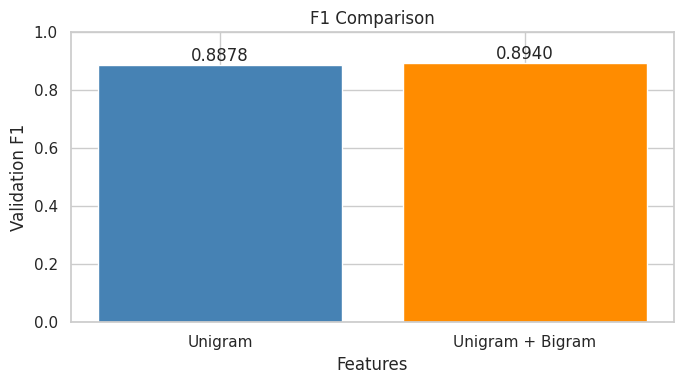

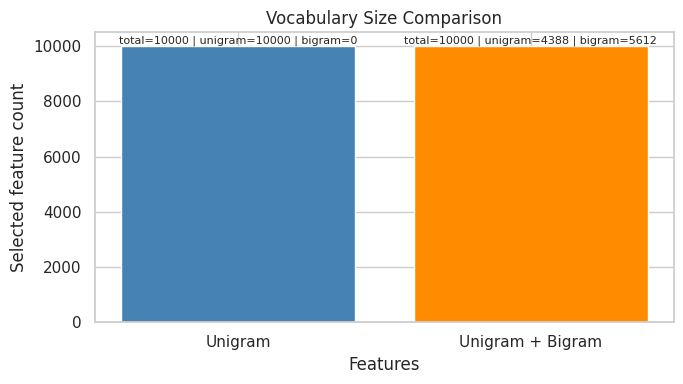

In [33]:
plt.figure(figsize=(7, 4))
bars = plt.bar(ngram_comparison["Features"], ngram_comparison["F1"], color=["steelblue", "darkorange"])
plt.title("F1 Comparison")
plt.xlabel("Features")
plt.ylabel("Validation F1")
plt.ylim(0, 1)
for bar, val in zip(bars, ngram_comparison["F1"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{val:.4f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
bars = plt.bar(ngram_comparison["Features"], ngram_comparison["Vocabulary"], color=["steelblue", "darkorange"])
plt.title("Vocabulary Size Comparison")
plt.xlabel("Features")
plt.ylabel("Selected feature count")
for bar, row in zip(bars, ngram_comparison.to_dict("records")):
    text = f"total={row['Vocabulary']} | unigram={row['Unigram Features']} | bigram={row['Bigram Features']}"
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), text, ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


# 19. Evaluation

Đánh giá lại ba model chính trên cùng Validation và đối chiếu với Experiment 3. Không train lại và không dùng Test.


## 19.1 Metrics Calculation

In [34]:
main_predictions = {
    "TF-IDF + Logistic Regression": y_val_pred,
    "Average Word2Vec + Logistic Regression": lr_w2v_model.predict(X_val_w2v),
    "TF-IDF + Linear SVM": svm_model.predict(X_val),
}
evaluation_rows = []
for name, pred in main_predictions.items():
    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, average="binary", pos_label=1, zero_division=0),
        "Recall": recall_score(y_val, pred, average="binary", pos_label=1, zero_division=0),
        "F1": f1_score(y_val, pred, average="binary", pos_label=1, zero_division=0),
    })
evaluation_table = pd.DataFrame(evaluation_rows)

comparison_metrics = comparison_table.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]
evaluation_metrics = evaluation_table.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]
assert np.allclose(comparison_metrics.loc[evaluation_metrics.index], evaluation_metrics)
print("Evaluation agrees with Experiment 3.")


Evaluation agrees with Experiment 3.


## 19.2 Model Evaluation Table

In [35]:
display(evaluation_table.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
}))
metric_rows = comparison_table[[
    "Model", "Representation", "Classifier", "Training Time (s)",
    "Vocabulary Size", "Accuracy", "Precision", "Recall", "F1",
]]
results_table = update_results_csv(metric_rows)


,Model,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,0.8868,0.8801,0.8956,0.8878
1,Average Word2Vec + Logistic Regression,0.8695,0.8672,0.8726,0.8699
2,TF-IDF + Linear SVM,0.8856,0.8806,0.8922,0.8864


# 20. Confusion Matrix

## 20.1 Confusion Matrix Visualization

Rows là Actual, columns là Predicted; labels theo thứ tự 0=Negative, 1=Positive. Cả ba matrix được tính trên Validation.


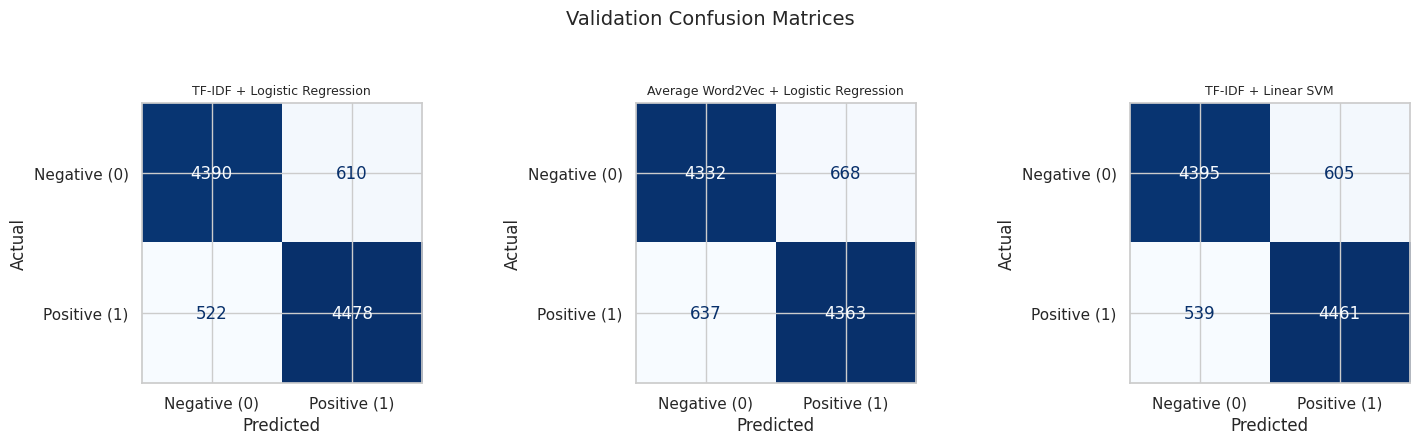

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = [0, 1]
class_names = ["Negative (0)", "Positive (1)"]
confusion_matrices = {}
error_counts = {}
for name, pred in main_predictions.items():
    matrix = confusion_matrix(y_val, pred, labels=class_labels)
    confusion_matrices[name] = matrix
    tn, fp, fn, tp = matrix.ravel()
    error_counts[name] = {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Validation Confusion Matrices", fontsize=14)
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_names)
    disp.plot(ax=ax, values_format="d", colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


## 20.2 TP, TN, FP, FN

In [37]:
error_counts_table = pd.DataFrame([
    {"Model": name, **counts, "Total Errors": counts["FP"] + counts["FN"]}
    for name, counts in error_counts.items()
])
display(error_counts_table)


,Model,TN,FP,FN,TP,Total Errors
0,TF-IDF + Logistic Regression,4390,610,522,4478,1132
1,Average Word2Vec + Logistic Regression,4332,668,637,4363,1305
2,TF-IDF + Linear SVM,4395,605,539,4461,1144


## 20.3 Error Statistics

Negative class errors are FP; Positive class errors are FN. Rates are normalized by the number of actual samples in each class. Equal values are reported as ties.


In [38]:
error_stats = []
for name, c in error_counts.items():
    tn, fp, fn, tp = c["TN"], c["FP"], c["FN"], c["TP"]
    neg_n, pos_n = tn + fp, fn + tp
    errors = fp + fn
    error_stats.append({
        "Model": name, "FP": fp, "FN": fn, "Total Errors": errors,
        "FP / Total Errors": fp / errors if errors else 0.0,
        "FN / Total Errors": fn / errors if errors else 0.0,
        "Negative Error Rate": fp / neg_n if neg_n else 0.0,
        "Positive Error Rate": fn / pos_n if pos_n else 0.0,
        "Negative Recall": tn / neg_n if neg_n else 0.0,
        "Positive Recall": tp / pos_n if pos_n else 0.0,
        "Positive Precision": tp / (tp + fp) if (tp + fp) else 0.0,
    })
error_statistics = pd.DataFrame(error_stats)
display(error_statistics.style.format({
    "FP / Total Errors": "{:.4f}", "FN / Total Errors": "{:.4f}",
    "Negative Error Rate": "{:.4f}", "Positive Error Rate": "{:.4f}",
    "Negative Recall": "{:.4f}", "Positive Recall": "{:.4f}",
    "Positive Precision": "{:.4f}",
}))

for _, row in error_statistics.iterrows():
    print()
    print(row["Model"])
    abs_class = "Negative" if row["FP"] > row["FN"] else "Positive" if row["FN"] > row["FP"] else "Tie"
    rate_class = (
        "Negative" if row["Negative Error Rate"] > row["Positive Error Rate"]
        else "Positive" if row["Positive Error Rate"] > row["Negative Error Rate"]
        else "Tie"
    )
    fp_fn = "FP" if row["FP"] > row["FN"] else "FN" if row["FN"] > row["FP"] else "Tie"
    print("More absolute class errors:", abs_class)
    print("Higher class error rate:", rate_class)
    print("More frequent error type:", fp_fn)
    print(f"Positive precision: {row['Positive Precision']:.4f}")
    print(f"Positive recall: {row['Positive Recall']:.4f}")


,Model,FP,FN,Total Errors,FP / Total Errors,FN / Total Errors,Negative Error Rate,Positive Error Rate,Negative Recall,Positive Recall,Positive Precision
0,TF-IDF + Logistic Regression,610,522,1132,0.5389,0.4611,0.1220,0.1044,0.8780,0.8956,0.8801
1,Average Word2Vec + Logistic Regression,668,637,1305,0.5119,0.4881,0.1336,0.1274,0.8664,0.8726,0.8672
2,TF-IDF + Linear SVM,605,539,1144,0.5288,0.4712,0.1210,0.1078,0.8790,0.8922,0.8806



TF-IDF + Logistic Regression
More absolute class errors: Negative
Higher class error rate: Negative
More frequent error type: FP
Positive precision: 0.8801
Positive recall: 0.8956

Average Word2Vec + Logistic Regression
More absolute class errors: Negative
Higher class error rate: Negative
More frequent error type: FP
Positive precision: 0.8672
Positive recall: 0.8726

TF-IDF + Linear SVM
More absolute class errors: Negative
Higher class error rate: Negative
More frequent error type: FP
Positive precision: 0.8806
Positive recall: 0.8922


### Save selected model confusion matrix

Chọn F1 Validation cao nhất; thứ tự A, B, C trong main_predictions là tie-break. Lưu matrix được chọn vào confusion_matrix.png trong thư mục làm việc hiện tại.


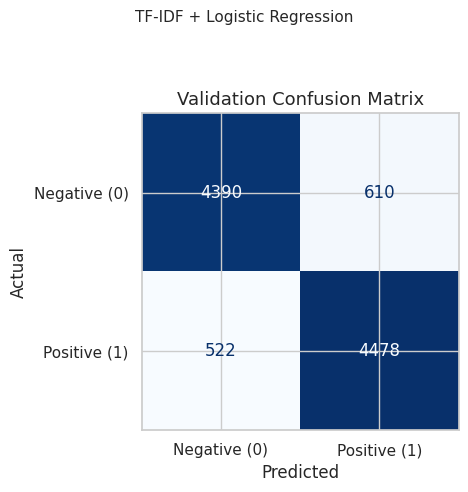

Selected model: TF-IDF + Logistic Regression
Saved: /home/nguyenducthang/NLP/Lab4/confusion_matrix.png


In [39]:
f1_by_model = evaluation_table.set_index("Model")["F1"]
selected_model = max(main_predictions.keys(), key=lambda name: f1_by_model.loc[name])
selected_matrix = confusion_matrices[selected_model]

fig, ax = plt.subplots(figsize=(5.5, 5))
selected_disp = ConfusionMatrixDisplay(confusion_matrix=selected_matrix, display_labels=class_names)
selected_disp.plot(ax=ax, values_format="d", colorbar=False, cmap="Blues")
ax.set_title("Validation Confusion Matrix", fontsize=13)
fig.suptitle(selected_model, y=0.98, fontsize=11)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
fig.tight_layout(rect=[0, 0, 1, 0.92])
CONFUSION_MATRIX_PATH = LAB_DIRECTORY / "confusion_matrix.png"
fig.savefig(CONFUSION_MATRIX_PATH, dpi=160, bbox_inches="tight")
plt.show()
print("Selected model:", selected_model)
print("Saved:", CONFUSION_MATRIX_PATH.resolve())


# 21. Error Analysis

Dùng model được chọn ở mục 20 theo Validation F1. Các loại lỗi được xác định bằng nhãn thật/dự đoán; ngôn ngữ giải thích là giả thuyết dựa trên clues quan sát được, cần sinh viên xác nhận.


## 21.1 Select Model and Extract Predictions

In [40]:
from collections import Counter

MODEL_ORDER = [
    "TF-IDF + Logistic Regression",
    "Average Word2Vec + Logistic Regression",
    "TF-IDF + Linear SVM",
]
selected_model_name = max(MODEL_ORDER, key=lambda name: f1_by_model[name])
selected_y_pred = np.asarray(main_predictions[selected_model_name])
selected_estimator = {
    MODEL_ORDER[0]: lr_model,
    MODEL_ORDER[1]: lr_w2v_model,
    MODEL_ORDER[2]: svm_model,
}[selected_model_name]
selected_X_val = X_val_w2v if selected_model_name == MODEL_ORDER[1] else X_val

if hasattr(selected_estimator, "predict_proba"):
    selected_positive_probability = selected_estimator.predict_proba(selected_X_val)[:, list(selected_estimator.classes_).index(1)]
    selected_decision_scores = None
    selected_score_type = "Positive probability"
else:
    selected_positive_probability = None
    selected_decision_scores = selected_estimator.decision_function(selected_X_val)
    selected_score_type = "Decision score, not probability"

print("Selected using Validation F1:", selected_model_name)
print(f"Validation F1: {f1_by_model[selected_model_name]:.4f}")
print("Score type:", selected_score_type)


Selected using Validation F1: TF-IDF + Logistic Regression
Validation F1: 0.8878
Score type: Positive probability


## 21.2 Correctly and Incorrectly Classified Samples

Lấy mẫu có seed 2026; chọn ít nhất một đúng Positive, một đúng Negative và cả FP/FN nếu có. Không sửa nội dung reviews.


In [41]:
true_array = np.asarray(y_val)
correct_ids = np.flatnonzero(selected_y_pred == true_array)
fp_ids = np.flatnonzero((true_array == 0) & (selected_y_pred == 1))
fn_ids = np.flatnonzero((true_array == 1) & (selected_y_pred == 0))
rng = np.random.default_rng(2026)

def choose_sample_ids(indices, count):
    indices = np.asarray(indices)
    if len(indices) == 0:
        return []
    return rng.choice(indices, size=min(count, len(indices)), replace=False).tolist()

correct_selected = choose_sample_ids(correct_ids[true_array[correct_ids] == 1], 1)
correct_selected += choose_sample_ids(
    [i for i in correct_ids if true_array[i] == 0 and i not in correct_selected], 1
)
correct_selected += choose_sample_ids(
    [i for i in correct_ids if i not in correct_selected],
    max(0, 3 - len(correct_selected)),
)
error_selected = choose_sample_ids(fp_ids, 1) + choose_sample_ids(fn_ids, 1)
remaining = [i for i in np.flatnonzero(selected_y_pred != true_array) if i not in error_selected]
error_selected += choose_sample_ids(remaining, max(0, 3 - len(error_selected)))

print("Correct examples selected:", len(correct_selected))
print("Misclassified examples selected:", len(error_selected))
print("Available FP:", len(fp_ids), "Available FN:", len(fn_ids))


Correct examples selected: 3
Misclassified examples selected: 3
Available FP: 610 Available FN: 522


## 21.3 Evidence, Error Table, and Error Summary

In [42]:
train_token_counts = Counter(token for review in train_tokens for token in review)
positive_cues = {"excellent", "great", "amazing", "wonderful", "best", "enjoyed", "love", "perfect"}
negative_cues = {"awful", "terrible", "worst", "boring", "poor", "bad", "waste", "hate"}
negation_cues = {"not", "never", "no", "neither", "nt"}

def inspect_review(text):
    tokens = simple_preprocess(str(text), deacc=False)
    token_set = set(tokens)
    vocabulary = w2v_model.wv.key_to_index if selected_model_name == MODEL_ORDER[1] else vectorizer.vocabulary_
    rare_oov = list(dict.fromkeys(t for t in tokens if t not in vocabulary or train_token_counts[t] <= 2))
    return {
        "Word count": len(str(text).split()),
        "Negation": ", ".join(sorted(token_set & negation_cues)) or "None detected",
        "Positive cues": ", ".join(sorted(token_set & positive_cues)) or "None detected",
        "Negative cues": ", ".join(sorted(token_set & negative_cues)) or "None detected",
        "Low-frequency/OOV": ", ".join(rare_oov[:10]) or "None detected",
    }

analysis_rows = []
full_review_rows = []
for example_id in correct_selected + error_selected:
    text = str(val_data["text"].iloc[example_id])
    actual = int(true_array[example_id])
    predicted = int(selected_y_pred[example_id])
    outcome = "Correct" if actual == predicted else "False Positive" if actual == 0 else "False Negative"
    evidence = inspect_review(text)
    score = (
        f"p(positive)={selected_positive_probability[example_id]:.4f}"
        if selected_positive_probability is not None
        else f"decision score={selected_decision_scores[example_id]:.4f}"
    )
    clues = []
    if evidence["Negation"] != "None detected":
        clues.append("negation present")
    if evidence["Word count"] < 50:
        clues.append("short review")
    if evidence["Low-frequency/OOV"] != "None detected":
        clues.append("low-frequency or OOV terms")
    if evidence["Positive cues"] != "None detected" and evidence["Negative cues"] != "None detected":
        clues.append("mixed cue words")
    analysis_rows.append({
        "Example ID": int(example_id),
        "Text": text[:240] + ("..." if len(text) > 240 else ""),
        "True Label": actual,
        "Predicted Label": predicted,
        "Error Type": outcome,
        "Score": score,
        "Evidence": "; ".join(f"{k}: {v}" for k, v in evidence.items()),
        "Analysis": f"Predicted {predicted} while actual label is {actual}; {score}.",
        "Possible Causes": "; ".join(clues) if clues else "No simple observable clue; inspect manually.",
        "Student-verified Cause": "Pending student verification",
    })
    full_review_rows.append({"Example ID": int(example_id), "Error Type": outcome, "Complete Review": text})

error_analysis_table = pd.DataFrame(analysis_rows)
complete_reviews_table = pd.DataFrame(full_review_rows)
display(error_analysis_table)
display(complete_reviews_table)

train_label_counts = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
selected_cm = confusion_matrix(true_array, selected_y_pred, labels=[0, 1])
tn, fp, fn, tp = selected_cm.ravel()
n_negative, n_positive = tn + fp, fn + tp
error_summary = {
    "Model": selected_model_name,
    "Validation Accuracy": accuracy_score(true_array, selected_y_pred),
    "Validation Precision": precision_score(true_array, selected_y_pred, average="binary", pos_label=1, zero_division=0),
    "Validation Recall": recall_score(true_array, selected_y_pred, average="binary", pos_label=1, zero_division=0),
    "Validation F1": f1_score(true_array, selected_y_pred, average="binary", pos_label=1, zero_division=0),
    "Correct": int(np.sum(selected_y_pred == true_array)),
    "Incorrect": int(np.sum(selected_y_pred != true_array)),
    "FP": int(fp), "FN": int(fn),
    "Negative error rate": fp / n_negative if n_negative else 0.0,
    "Positive error rate": fn / n_positive if n_positive else 0.0,
    "Most frequent error direction": "FP" if fp > fn else "FN" if fn > fp else "Tie",
    "Train class counts": {0: int(train_label_counts.loc[0]), 1: int(train_label_counts.loc[1])},
}
print(error_summary)


,Example ID,Text,True Label,Predicted Label,Error Type,Score,Evidence,Analysis,Possible Causes,Student-verified Cause
0,8479,"LIFEFORCE is an extremely schizophrenic movie, based on Colin Wilson`s novel The Space Vampires the script ignores most of the novel`s concepts and structure ( Indeed it owes more to the QUATERMASS serials than the novel ) but the scenes it...",1,1,Correct,p(positive)=0.6924,"Word count: 335; Negation: not; Positive cues: great; Negative cues: None detected; Low-frequency/OOV: quatermass, carlson, beleaguered, brits, spoils, realising, untill, hid, bedrooms, pyrotechnics",Predicted 1 while actual label is 1; p(positive)=0.6924.,negation present; low-frequency or OOV terms,Pending student verification
1,1676,"... in search of the cheesiest ""so bad it's good"" movie, I've repeatedly laughed at the first fifteen minutes of various films, only to be left disappointed and bored at the end. Not this time!!! My eyes teared up, my belly and my cheeks ac...",0,0,Correct,p(positive)=0.2557,"Word count: 143; Negation: not; Positive cues: None detected; Negative cues: bad; Low-frequency/OOV: cheesiest, teared, cheeks, ached, subpar, dives, whoopass, whatchugonnado, infamously, goateed",Predicted 0 while actual label is 0; p(positive)=0.2557.,negation present; low-frequency or OOV terms,Pending student verification
2,256,"Essentially this is a dreadful film with a few features that may or may not redeem it for you, depending on how much you want them to. In ""opening up"" ""The Red Green Show"" for the big screen, the filmmakers jettisoned the rustic charm caref...",0,0,Correct,p(positive)=0.3455,"Word count: 185; Negation: not; Positive cues: None detected; Negative cues: boring; Low-frequency/OOV: jettisoned, rustic, honed, possum, lodge, blandly, embellished, devised, plotline, offscreen",Predicted 0 while actual label is 0; p(positive)=0.3455.,negation present; low-frequency or OOV terms,Pending student verification
3,6589,"28 years before 9/11, there was another 9/11 which represented a key date in the history of Chile, South America and the whole world. This was the date in 1973 when a bloody coup in Chile deposed Salvador Allende the first Marxist president...",0,1,False Positive,p(positive)=0.6612,"Word count: 282; Negation: never, no; Positive cues: None detected; Negative cues: None detected; Low-frequency/OOV: chile, deposed, salvador, allende, marxist, democratically, chilean, capitalism, socialism, disputed",Predicted 1 while actual label is 0; p(positive)=0.6612.,negation present; low-frequency or OOV terms,Pending student verification
4,3818,"Just watched this after my mother brought it back from America for me, was dreading watching this after all the negative comments on here but I have to say, yes the acting is cheesy, some of the effects are laughable.<br /><br />But you hav...",1,0,False Negative,p(positive)=0.2743,"Word count: 126; Negation: not; Positive cues: enjoyed; Negative cues: None detected; Low-frequency/OOV: dreading, ahh",Predicted 0 while actual label is 1; p(positive)=0.2743.,negation present; low-frequency or OOV terms,Pending student verification
5,4816,"Okay, I think we're all agreed that Michael Jackson was the low point.<br /><br />And the special effects too. But, please, keep in mind that this was NOT a big-budget film, okay? Not every film gets as much of a budget as Harry Potter or S...",1,0,False Negative,p(positive)=0.0742,"Word count: 103; Negation: not; Positive cues: None detected; Negative cues: bad, waste; Low-frequency/OOV: None detected",Predicted 0 while actual label is 1; p(positive)=0.0742.,negation present,Pending student verification


,Example ID,Error Type,Complete Review
0,8479,Correct,"LIFEFORCE is an extremely schizophrenic movie, based on Colin Wilson`s novel The Space Vampires the script ignores most of the novel`s concepts and structure ( Indeed it owes more to the QUATERMASS serials than the novel ) but the scenes it does leave in from the novel are nearly identical to th..."
1,1676,Correct,"... in search of the cheesiest ""so bad it's good"" movie, I've repeatedly laughed at the first fifteen minutes of various films, only to be left disappointed and bored at the end. Not this time!!! My eyes teared up, my belly and my cheeks ached from laughing so hard throughout the movie. Sure, Hu..."
2,256,Correct,"Essentially this is a dreadful film with a few features that may or may not redeem it for you, depending on how much you want them to. In ""opening up"" ""The Red Green Show"" for the big screen, the filmmakers jettisoned the rustic charm carefully honed over a decade's worth of episodes set in and ..."
3,6589,False Positive,"28 years before 9/11, there was another 9/11 which represented a key date in the history of Chile, South America and the whole world. This was the date in 1973 when a bloody coup in Chile deposed Salvador Allende the first Marxist president elected democratically anywhere in the world and put an..."
4,3818,False Negative,"Just watched this after my mother brought it back from America for me, was dreading watching this after all the negative comments on here but I have to say, yes the acting is cheesy, some of the effects are laughable.<br /><br />But you have to remember this was meant to be 1898 not 2005, and fo..."
5,4816,False Negative,"Okay, I think we're all agreed that Michael Jackson was the low point.<br /><br />And the special effects too. But, please, keep in mind that this was NOT a big-budget film, okay? Not every film gets as much of a budget as Harry Potter or Star Wars.<br /><br />However, I thought it was pretty fu..."


{'Model': 'TF-IDF + Logistic Regression', 'Validation Accuracy': 0.8868, 'Validation Precision': 0.8801100628930818, 'Validation Recall': 0.8956, 'Validation F1': 0.887787470261697, 'Correct': 8868, 'Incorrect': 1132, 'FP': 610, 'FN': 522, 'Negative error rate': np.float64(0.122), 'Positive error rate': np.float64(0.1044), 'Most frequent error direction': 'FP', 'Train class counts': {0: 15000, 1: 15000}}


## 21.4 Save Error Analysis

In [43]:
def markdown_safe(value):
    return str(value).replace("|", "¦")

lines = [
    "# LAB 04 — Error Analysis",
    "",
    f"Selected model: {selected_model_name}",
    f"Validation metrics: Accuracy {error_summary['Validation Accuracy']:.4f}; Precision {error_summary['Validation Precision']:.4f}; Recall {error_summary['Validation Recall']:.4f}; F1 {error_summary['Validation F1']:.4f}.",
    f"Correct: {error_summary['Correct']}; incorrect: {error_summary['Incorrect']}; FP: {fp}; FN: {fn}.",
    f"Negative error rate: {error_summary['Negative error rate']:.4f}; positive error rate: {error_summary['Positive error rate']:.4f}.",
    f"Most frequent error direction: {error_summary['Most frequent error direction']}.",
    f"Training class distribution (Negative=0, Positive=1): {error_summary['Train class counts']}.",
    "",
    "Possible causes are observable-clue hypotheses, not proven causes. Student verification is pending.",
]
for _, row in error_analysis_table.iterrows():
    full_text = complete_reviews_table.loc[
        complete_reviews_table["Example ID"] == row["Example ID"], "Complete Review"
    ].iloc[0]
    lines.extend([
        "",
        f"## Example {int(row['Example ID'])} — {row['Error Type']}",
        f"True label: {row['True Label']}; predicted label: {row['Predicted Label']}; score: {row['Score']}.",
        f"Evidence: {row['Evidence']}",
        f"Neutral technical description: {row['Analysis']}",
        f"Possible causes (hypotheses): {row['Possible Causes']}",
        "Student-verified Cause: Pending student verification.",
        "",
        "Complete original review:",
        "",
        full_text,
    ])
generated_error = chr(10).join(lines)
start_marker = "<!-- CODEX_ERROR_ANALYSIS_START -->"
end_marker = "<!-- CODEX_ERROR_ANALYSIS_END -->"
error_path = LAB_DIRECTORY / "error_analysis.md"
if error_path.exists():
    old_text = error_path.read_text(encoding="utf-8")
    if start_marker in old_text and end_marker in old_text:
        before = old_text.split(start_marker)[0]
        after = old_text.split(end_marker, 1)[1]
        old_text = before + start_marker + chr(10) + generated_error + chr(10) + end_marker + after
    else:
        old_text = old_text.rstrip() + chr(10) * 2 + start_marker + chr(10) + generated_error + chr(10) + end_marker + chr(10)
else:
    old_text = start_marker + chr(10) + generated_error + chr(10) + end_marker + chr(10)
error_path.write_text(old_text, encoding="utf-8")
print("Saved error analysis:", error_path)


Saved error analysis: /home/nguyenducthang/NLP/Lab4/error_analysis.md


# 22. Inspect Model Weights

Dùng Model A: TF-IDF + Logistic Regression. Dấu hệ số được quy về class 1 (Positive); dấu dương đẩy logit về Positive, dấu âm đẩy về Negative.


## 22.1 Top Positive and Negative Features

In [44]:
feature_names = vectorizer.get_feature_names_out()
assert len(feature_names) == lr_model.coef_.shape[1]
assert list(lr_model.classes_).count(1) == 1
positive_class_index = list(lr_model.classes_).index(1)
weights = lr_model.coef_[0]
positive_weights = weights if positive_class_index == 1 else -weights

positive_idx = np.argsort(positive_weights)[::-1][:15]
negative_idx = np.argsort(positive_weights)[:15]
top_positive_features = pd.DataFrame({
    "Rank": np.arange(1, len(positive_idx) + 1),
    "Feature": feature_names[positive_idx],
    "Weight": positive_weights[positive_idx],
})
top_negative_features = pd.DataFrame({
    "Rank": np.arange(1, len(negative_idx) + 1),
    "Feature": feature_names[negative_idx],
    "Weight": positive_weights[negative_idx],
})
display(top_positive_features.style.format({"Weight": "{:.4f}"}))
display(top_negative_features.style.format({"Weight": "{:.4f}"}))


,Rank,Feature,Weight
0,1,great,7.5771
1,2,excellent,6.9556
2,3,best,4.9950
3,4,amazing,4.7518
4,5,wonderful,4.6847
5,6,perfect,4.6791
6,7,today,4.5467
7,8,brilliant,4.2460
8,9,highly,4.1763
9,10,loved,4.1320


,Rank,Feature,Weight
0,1,worst,-10.0644
1,2,bad,-7.6141
2,3,awful,-7.4464
3,4,boring,-6.7573
4,5,waste,-6.6216
5,6,terrible,-5.9898
6,7,poor,-5.6866
7,8,worse,-4.8122
8,9,nothing,-4.8067
9,10,dull,-4.6984


## 22.2 Visualization and Student Interpretation

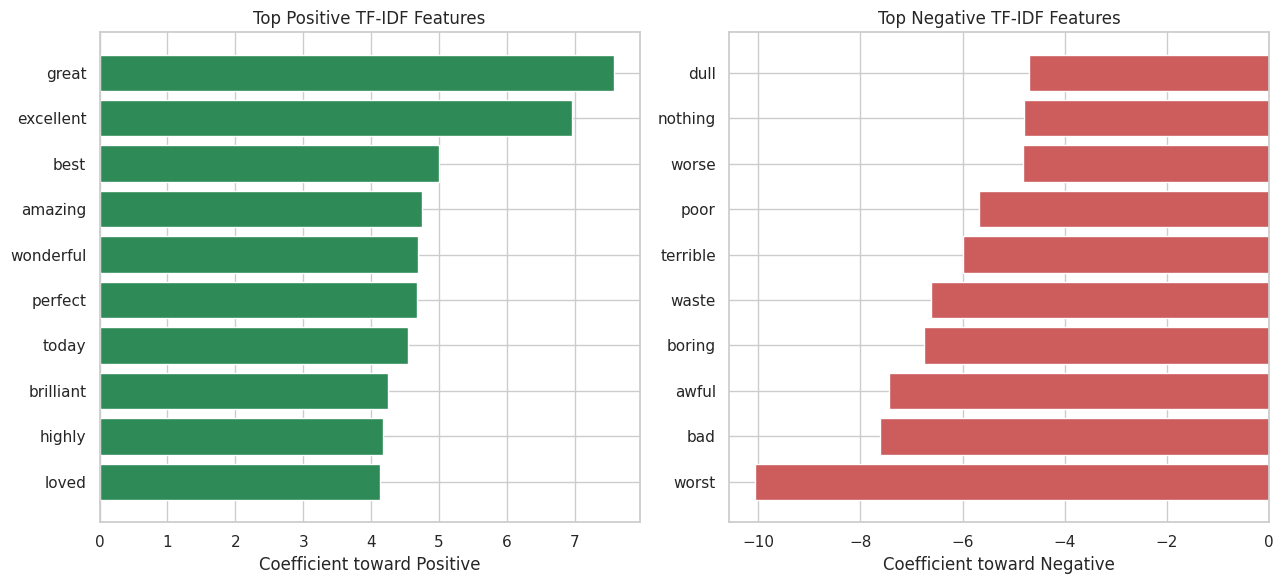

### Learned feature evidence

**Top Positive:** great (7.577), excellent (6.956), best (4.995), amazing (4.752), wonderful (4.685), perfect (4.679), today (4.547), brilliant (4.246), highly (4.176), loved (4.132), favorite (4.088), fun (3.992), enjoyed (3.936), hilarious (3.895), well (3.479)

**Top Negative:** worst (-10.064), bad (-7.614), awful (-7.446), boring (-6.757), waste (-6.622), terrible (-5.990), poor (-5.687), worse (-4.812), nothing (-4.807), dull (-4.698), poorly (-4.502), minutes (-4.490), horrible (-4.315), fails (-4.262), unfortunately (-4.131)

Positive coefficients contribute toward class Positive; negative coefficients contribute toward class Negative. Coefficients are model associations, not guaranteed meanings or causal effects.

**Những feature này có thực sự có ý nghĩa đối với sentiment classification không?**

| Feature | Weight | Student evaluation |
|---|---:|---|
| | | Pending student response |

In [45]:
pos_plot = top_positive_features.head(10).sort_values("Weight")
neg_plot = top_negative_features.head(10).sort_values("Weight")
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(pos_plot["Feature"], pos_plot["Weight"], color="seagreen")
axes[0].set_title("Top Positive TF-IDF Features")
axes[0].set_xlabel("Coefficient toward Positive")
axes[1].barh(neg_plot["Feature"], neg_plot["Weight"], color="indianred")
axes[1].set_title("Top Negative TF-IDF Features")
axes[1].set_xlabel("Coefficient toward Negative")
fig.tight_layout()
plt.show()

weights_markdown = (
    "### Learned feature evidence" + chr(10) + chr(10)
    + "**Top Positive:** " + ", ".join(f"{r.Feature} ({r.Weight:.3f})" for r in top_positive_features.itertuples())
    + chr(10) + chr(10)
    + "**Top Negative:** " + ", ".join(f"{r.Feature} ({r.Weight:.3f})" for r in top_negative_features.itertuples())
    + chr(10) + chr(10)
    + "Positive coefficients contribute toward class Positive; negative coefficients contribute toward class Negative. "
    + "Coefficients are model associations, not guaranteed meanings or causal effects."
    + chr(10) + chr(10)
    + "**Những feature này có thực sự có ý nghĩa đối với sentiment classification không?**"
    + chr(10) + chr(10)
    + "| Feature | Weight | Student evaluation |" + chr(10)
    + "|---|---:|---|" + chr(10)
    + "| | | Pending student response |"
)
display(Markdown(weights_markdown))


# 23. Application — Sentiment Classification

Ứng dụng dùng model được chọn theo Validation F1. Không fit vectorizer hay train Word2Vec lại trên input mới.


## 23.1 Prediction Function and Application Examples

In [46]:
def predict_sentiment(text):
    if not isinstance(text, str):
        raise TypeError("Review input must be a string.")
    if not text.strip():
        raise ValueError("Review input cannot be empty or whitespace-only.")

    decision_score = None
    positive_probability = None
    if selected_model_name == MODEL_ORDER[0]:
        features, estimator = vectorizer.transform([text]), lr_model
    elif selected_model_name == MODEL_ORDER[1]:
        tokens = simple_preprocess(text, deacc=False)
        features = average_word_vectors(tokens, w2v_model).reshape(1, -1)
        estimator = lr_w2v_model
    else:
        features, estimator = vectorizer.transform([text]), svm_model

    label = int(estimator.predict(features)[0])
    if hasattr(estimator, "predict_proba"):
        positive_probability = float(estimator.predict_proba(features)[0, list(estimator.classes_).index(1)])
    else:
        decision_score = float(np.asarray(estimator.decision_function(features)).ravel()[0])

    return {
        "input_text": text,
        "predicted_label": label,
        "sentiment": "Positive" if label == 1 else "Negative",
        "positive_probability": positive_probability,
        "decision_score": decision_score,
        "model_name": selected_model_name,
    }

application_inputs = [
    "A wonderful, heartfelt film with excellent acting and a satisfying ending.",
    "A terrible and boring movie that was a complete waste of time.",
    "The performances were absolutely fantastic and the story was very engaging.",
    "I did not enjoy this film; it was never interesting and the ending was poor.",
    "The acting was great, but the plot was disappointing and too long.",
    "Well, that was just amazing... if you enjoy waiting two hours for nothing.",
]
application_outputs = [predict_sentiment(text) for text in application_inputs]
application_table = pd.DataFrame([{
    "Input Text": result["input_text"],
    "Predicted Sentiment": result["sentiment"],
    "Probability / Score": result["positive_probability"] if result["positive_probability"] is not None else result["decision_score"],
    "Model": result["model_name"],
    "Score Type": "Positive probability" if result["positive_probability"] is not None else "SVM decision score (not probability)",
} for result in application_outputs])
display(application_table.style.format({"Probability / Score": "{:.4f}"}))


,Input Text,Predicted Sentiment,Probability / Score,Model,Score Type
0,"A wonderful, heartfelt film with excellent acting and a satisfying ending.",Positive,0.9924,TF-IDF + Logistic Regression,Positive probability
1,A terrible and boring movie that was a complete waste of time.,Negative,0.0001,TF-IDF + Logistic Regression,Positive probability
2,The performances were absolutely fantastic and the story was very engaging.,Positive,0.9492,TF-IDF + Logistic Regression,Positive probability
3,I did not enjoy this film; it was never interesting and the ending was poor.,Negative,0.0741,TF-IDF + Logistic Regression,Positive probability
4,"The acting was great, but the plot was disappointing and too long.",Negative,0.1094,TF-IDF + Logistic Regression,Positive probability
5,"Well, that was just amazing... if you enjoy waiting two hours for nothing.",Positive,0.7763,TF-IDF + Logistic Regression,Positive probability


### Optional interactive demonstration

Nếu ipywidgets có trong môi trường thì notebook hiển thị ô nhập review; nếu không, dùng trực tiếp hàm predict_sentiment.


In [47]:
import importlib.util
if importlib.util.find_spec("ipywidgets") is not None:
    import ipywidgets as widgets
    review_box = widgets.Textarea(
        value="", placeholder="Type a movie review", description="Review:",
        layout=widgets.Layout(width="90%", height="100px"),
    )
    output_box = widgets.Output()
    def show_prediction(change):
        with output_box:
            output_box.clear_output()
            if change["new"].strip():
                display(predict_sentiment(change["new"]))
    review_box.observe(show_prediction, names="value")
    display(review_box, output_box)
else:
    print("ipywidgets unavailable; call predict_sentiment(text) directly.")


ipywidgets unavailable; call predict_sentiment(text) directly.


## 23.2 Final Test Evaluation

Sau khi cố định model theo Validation F1, đánh giá model đó đúng một lần trên Test, bằng representation đã fit trên Train. Test không ảnh hưởng đến việc chọn model.


In [48]:
if selected_model_name == MODEL_ORDER[0]:
    test_predictions = lr_model.predict(X_test)
elif selected_model_name == MODEL_ORDER[1]:
    test_predictions = lr_w2v_model.predict(X_test_w2v)
else:
    test_predictions = svm_model.predict(X_test)

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, average="binary", pos_label=1, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, average="binary", pos_label=1, zero_division=0),
    "F1": f1_score(y_test, test_predictions, average="binary", pos_label=1, zero_division=0),
}
test_result_table = pd.DataFrame([{"Model": selected_model_name, "Split": "Test", **test_metrics}])
display(test_result_table.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
}))
results_table = update_results_csv(test_result_table)


,Model,Split,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,Test,0.8885,0.8778,0.9026,0.8901


# 24. AI Assistance Statement

README receives an idempotent Codex assistance block. Existing user-authored content is retained; conceptual interpretations remain pending student verification.


In [49]:
readme_path = LAB_DIRECTORY / "README.md"
readme_start = "<!-- CODEX_AI_ASSISTANCE_START -->"
readme_end = "<!-- CODEX_AI_ASSISTANCE_END -->"
ai_lines = [
    "### AI Assistance Statement",
    "",
    "Tool: OpenAI Codex",
    "",
    "Purpose:",
    "- Code implementation assistance for LAB 04 Sections 13–23.",
    "- Debugging and sequential notebook execution.",
    "- Data processing, metrics, visualization, and technical documentation.",
    "",
    "Generated:",
    "- Notebook code for Sections 13–23.",
    "- Tables, metrics, plots, and validation error-analysis evidence generated by executed cells.",
    "- Coefficient evidence and a sentiment prediction demo.",
    "",
    "Modified:",
    "- classification.ipynb",
    "- results.csv",
    "- confusion_matrix.png",
    "- error_analysis.md",
    "- README.md",
    "",
    "Verified:",
    "- Full notebook execution from a clean kernel completed successfully.",
    "- Student interpretation and Student-verified Cause fields remain pending manual review.",
]
ai_section = chr(10).join(ai_lines)
if readme_path.exists():
    readme_text = readme_path.read_text(encoding="utf-8")
    if readme_start in readme_text and readme_end in readme_text:
        before = readme_text.split(readme_start)[0]
        after = readme_text.split(readme_end, 1)[1]
        readme_text = before + readme_start + chr(10) + ai_section + chr(10) + readme_end + after
    else:
        readme_text = readme_text.rstrip() + chr(10) * 2 + readme_start + chr(10) + ai_section + chr(10) + readme_end + chr(10)
else:
    readme_text = "# LAB 04 — Text Classification" + chr(10) * 2 + readme_start + chr(10) + ai_section + chr(10) + readme_end + chr(10)
readme_path.write_text(readme_text, encoding="utf-8")
print("Updated:", readme_path)


Updated: /home/nguyenducthang/NLP/Lab4/README.md
